# Week 3 Lab: Waves and the Fourier Transform

**Course:** Brain-Computer Interfacing

Each part has a solved example, then a practice task that is very close to the example. Read the example, run it, then copy and adapt it for the practice.

---

## Setup

- Part 1: where cosine and sine come from, and how a spinning arrow draws a wave.
- Part 2: the Fourier transform: how to find which waves are hidden inside a signal.
- Part 3: use the Fourier transform on real brain signals (EEG) recorded while a person imagined moving the left or right hand.

In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

plt.style.use('dark_background')
np.random.seed(42)

---

## Part 1: Waves from a Rotating Vector

### Example 1a: cosine and sine are projections

Imagine an arrow of length 1 that starts at the centre of a circle (the **unit circle**). The arrow makes an angle θ with the x-axis. This angle is called the **phase**.

- The shadow of the arrow on the x-axis has length `cos θ`.
- The shadow of the arrow on the y-axis has length `sin θ`.

That is all cos and sin are. You may remember from school: `cos θ = adjacent / hypotenuse` and `sin θ = opposite / hypotenuse`. A bigger triangle with the same angle gives the same ratios, so we can always use a hypotenuse of 1.

angle = 60° = 1.0472 rad
projection on x: cos = 0.5000   projection on y: sin = 0.8660
cos² + sin² = 1.0000   (the vector has length 1)

hypotenuse 1: adjacent = 0.500, adjacent / hypotenuse = 0.500, opposite / hypotenuse = 0.866
hypotenuse 2: adjacent = 1.000, adjacent / hypotenuse = 0.500, opposite / hypotenuse = 0.866
hypotenuse 5: adjacent = 2.500, adjacent / hypotenuse = 0.500, opposite / hypotenuse = 0.866


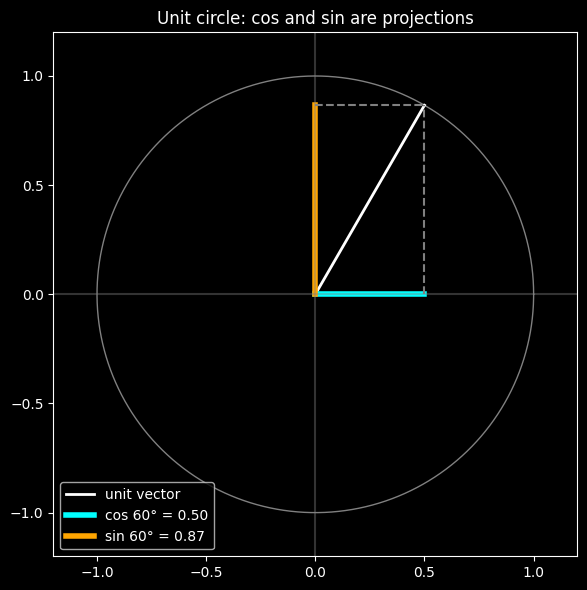

In [2]:
theta_deg = 60
theta = np.deg2rad(theta_deg)          # numpy works in radians: 360° = 2π
x_proj, y_proj = np.cos(theta), np.sin(theta)
print(f"angle = {theta_deg}° = {theta:.4f} rad")
print(f"projection on x: cos = {x_proj:.4f}   projection on y: sin = {y_proj:.4f}")
print(f"cos² + sin² = {x_proj**2 + y_proj**2:.4f}   (the vector has length 1)\n")

for hyp in [1, 2, 5]:
    adj, opp = hyp * np.cos(theta), hyp * np.sin(theta)
    print(f"hypotenuse {hyp}: adjacent = {adj:.3f}, adjacent / hypotenuse = {adj / hyp:.3f}, opposite / hypotenuse = {opp / hyp:.3f}")

circle = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(np.cos(circle), np.sin(circle), color='gray', linewidth=1)
ax.plot([0, x_proj], [0, y_proj], color='white', linewidth=2, label='unit vector')
ax.plot([0, x_proj], [0, 0], color='cyan', linewidth=4, label=f'cos {theta_deg}° = {x_proj:.2f}')
ax.plot([0, 0], [0, y_proj], color='orange', linewidth=4, label=f'sin {theta_deg}° = {y_proj:.2f}')
ax.plot([x_proj, x_proj], [0, y_proj], color='gray', linestyle='--')
ax.plot([0, x_proj], [y_proj, y_proj], color='gray', linestyle='--')
ax.axhline(0, color='gray', alpha=0.4)
ax.axvline(0, color='gray', alpha=0.4)
ax.set_aspect('equal')
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_title('Unit circle: cos and sin are projections')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

### Example 1b: lengths from angles

Why is this useful? You stand 23 m away from a building and look up at its top with an angle of 60°. How tall is the building?

1. `cos 60° = 23 / hypotenuse`, so the hypotenuse = 23 / 0.5 = 46 m.
2. `sin 60° = height / hypotenuse`, so the height = 46 × 0.87 ≈ 40 m.

In [3]:
distance = 23
angle = np.deg2rad(60)
hypotenuse = distance / np.cos(angle)
height = hypotenuse * np.sin(angle)
print(f"hypotenuse = {hypotenuse:.2f} m")
print(f"height     = {height:.2f} m")
print(f"same with tan = sin / cos: {distance * np.tan(angle):.2f} m")

hypotenuse = 46.00 m
height     = 39.84 m
same with tan = sin / cos: 39.84 m


### Example 1c: from a rotating vector to a wave

Now let the arrow spin. If it makes `f` full turns every second, we say its **frequency** is `f` Hz. After `t` seconds its angle is `θ = 2π f t` (one full turn = 2π).

Write down the x-shadow at every moment and plot it against time: you get a **cosine wave**. Do the same with the y-shadow: you get a **sine wave**.

The sine is just the cosine started a quarter turn (90° = π/2) later: `sin θ = cos(θ − π/2)`.

t: (200,), 0.0 s to 1.99 s
sin(θ) equals cos(θ − π/2): True


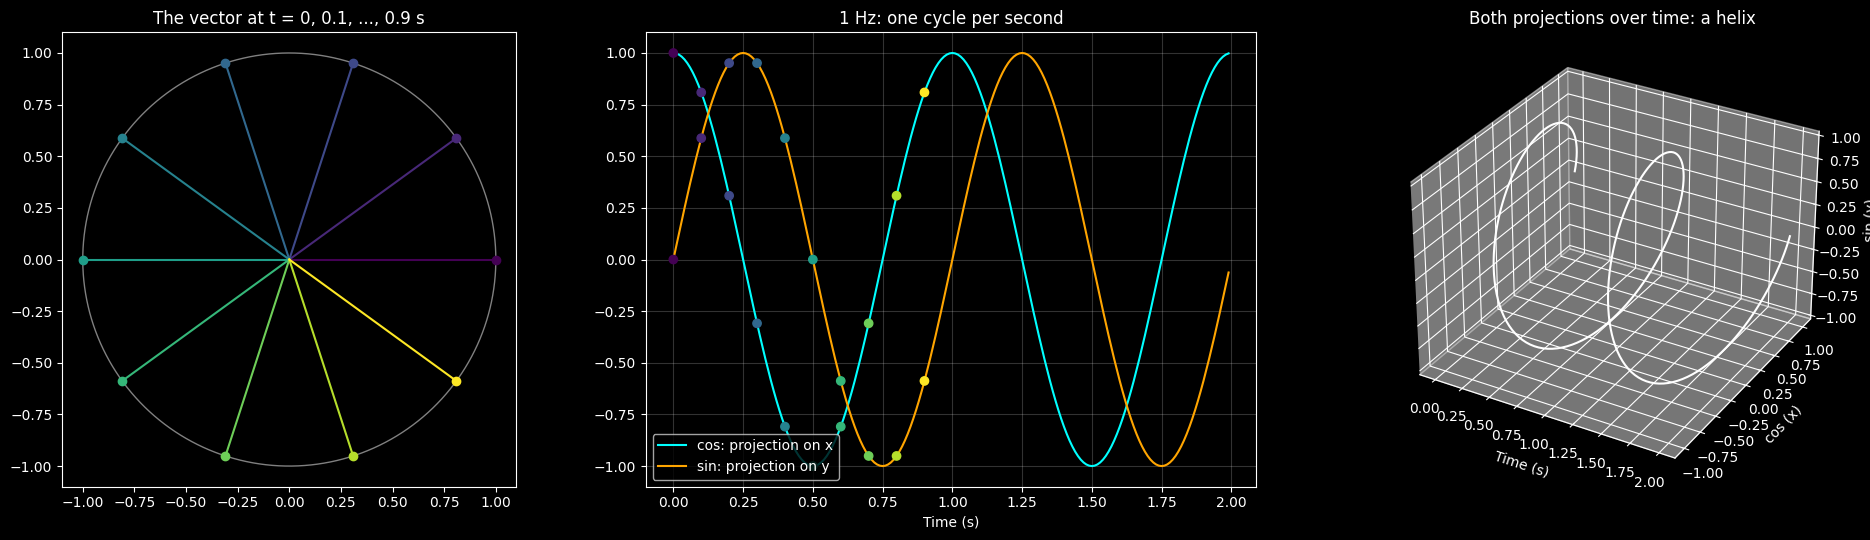

In [4]:
fs = 100                        # sampling rate: samples per second
t = np.arange(0, 2, 1 / fs)     # 2 s, step 1/fs
f = 1                           # 1 cycle per second
theta_t = 2 * np.pi * f * t     # angle of the vector at every sample
cos_wave = np.cos(theta_t)
sin_wave = np.sin(theta_t)
print(f"t: {t.shape}, {t[0]} s to {t[-1]} s")
print(f"sin(θ) equals cos(θ − π/2): {np.allclose(sin_wave, np.cos(theta_t - np.pi / 2))}")

marks = np.arange(0, 100, 10)                   # a few samples of the first cycle
colors = plt.cm.viridis(np.linspace(0, 1, len(marks)))

fig = plt.figure(figsize=(20, 5.5))
ax0 = fig.add_subplot(1, 3, 1)
ax0.plot(np.cos(circle), np.sin(circle), color='gray', linewidth=1)
for k, c in zip(marks, colors):
    ax0.plot([0, cos_wave[k]], [0, sin_wave[k]], color=c, linewidth=1.5)
    ax0.plot(cos_wave[k], sin_wave[k], 'o', color=c)
ax0.set_aspect('equal')
ax0.set_title('The vector at t = 0, 0.1, ..., 0.9 s')

ax1 = fig.add_subplot(1, 3, 2)
ax1.plot(t, cos_wave, color='cyan', label='cos: projection on x')
ax1.plot(t, sin_wave, color='orange', label='sin: projection on y')
ax1.scatter(t[marks], cos_wave[marks], color=colors, zorder=3)
ax1.scatter(t[marks], sin_wave[marks], color=colors, zorder=3)
ax1.set_xlabel('Time (s)')
ax1.set_title(f'{f} Hz: one cycle per second')
ax1.legend(loc='lower left')
ax1.grid(True, alpha=0.2)

ax2 = fig.add_subplot(1, 3, 3, projection='3d')
ax2.plot(t, cos_wave, sin_wave, color='white')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('cos (x)')
ax2.set_zlabel('sin (y)')
ax2.set_title('Both projections over time: a helix')
plt.tight_layout()
plt.show()

In 3D the spinning arrow draws a spring (a helix). Look at it from the side and you see the cosine; from above, the sine; along the time axis, the circle.

### Example 1d: amplitude, frequency and phase

Every wave in this lab has the form `A · cos(2π f t + φ)`. Only three numbers describe it:

- Amplitude `A`: how long the arrow is → how tall the wave is.
- Frequency `f`: how fast the arrow spins → how many waves per second.
- Phase `φ`: where the arrow starts at t = 0 → the wave is shifted left or right.

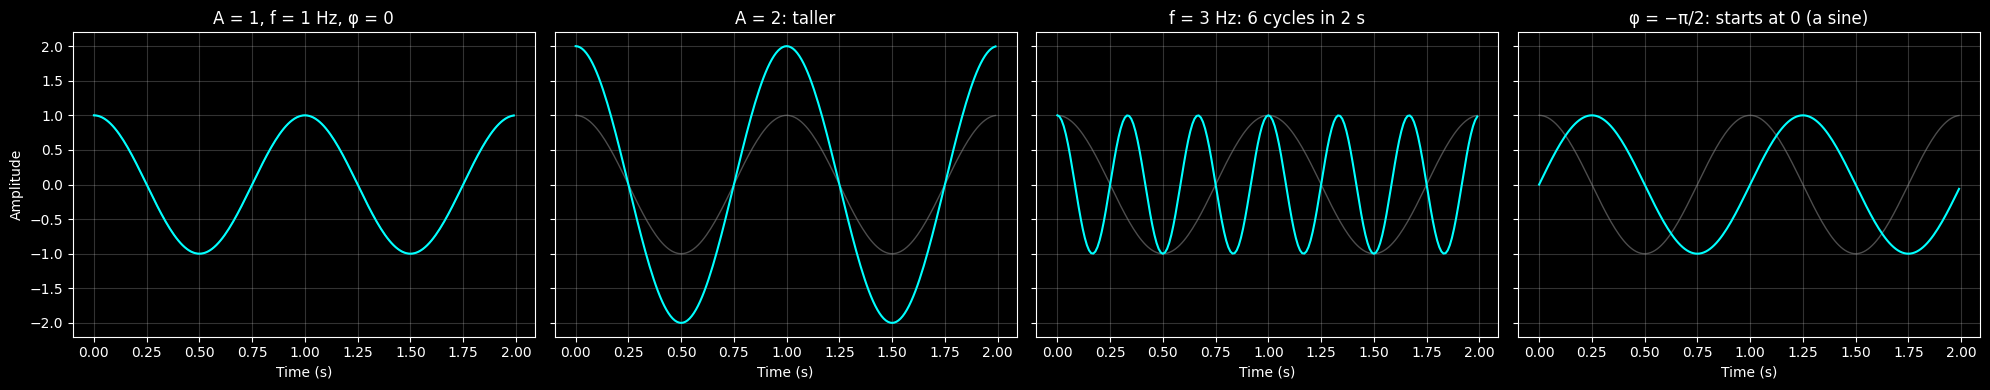

In [5]:
def wave(t, amp=1.0, freq=1.0, phase=0.0):
    return amp * np.cos(2 * np.pi * freq * t + phase)

variants = [
    (dict(), 'A = 1, f = 1 Hz, φ = 0'),
    (dict(amp=2), 'A = 2: taller'),
    (dict(freq=3), 'f = 3 Hz: 6 cycles in 2 s'),
    (dict(phase=-np.pi / 2), 'φ = −π/2: starts at 0 (a sine)'),
]
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, (params, title) in zip(axes, variants):
    ax.plot(t, wave(t), color='gray', linewidth=1, alpha=0.6)
    ax.plot(t, wave(t, **params), color='cyan', linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel('Time (s)')
    ax.grid(True, alpha=0.2)
axes[0].set_ylabel('Amplitude')
plt.tight_layout()
plt.show()

### Practice 1 (10 min)

Hint: look at how `t` and `theta_t` were made in Example 1c.

1. `t_p`: time from 0 to 2 s with 128 samples per second (256 samples).
2. `wave_a`: a cosine with amplitude 2 and frequency 3 Hz.
3. `wave_b`: a sine with amplitude 0.5 and frequency 10 Hz.
4. `wave_b_cos`: the same wave as `wave_b`, but written with `np.cos` (shift the phase by π/2).
5. `mix = wave_a + wave_b`.

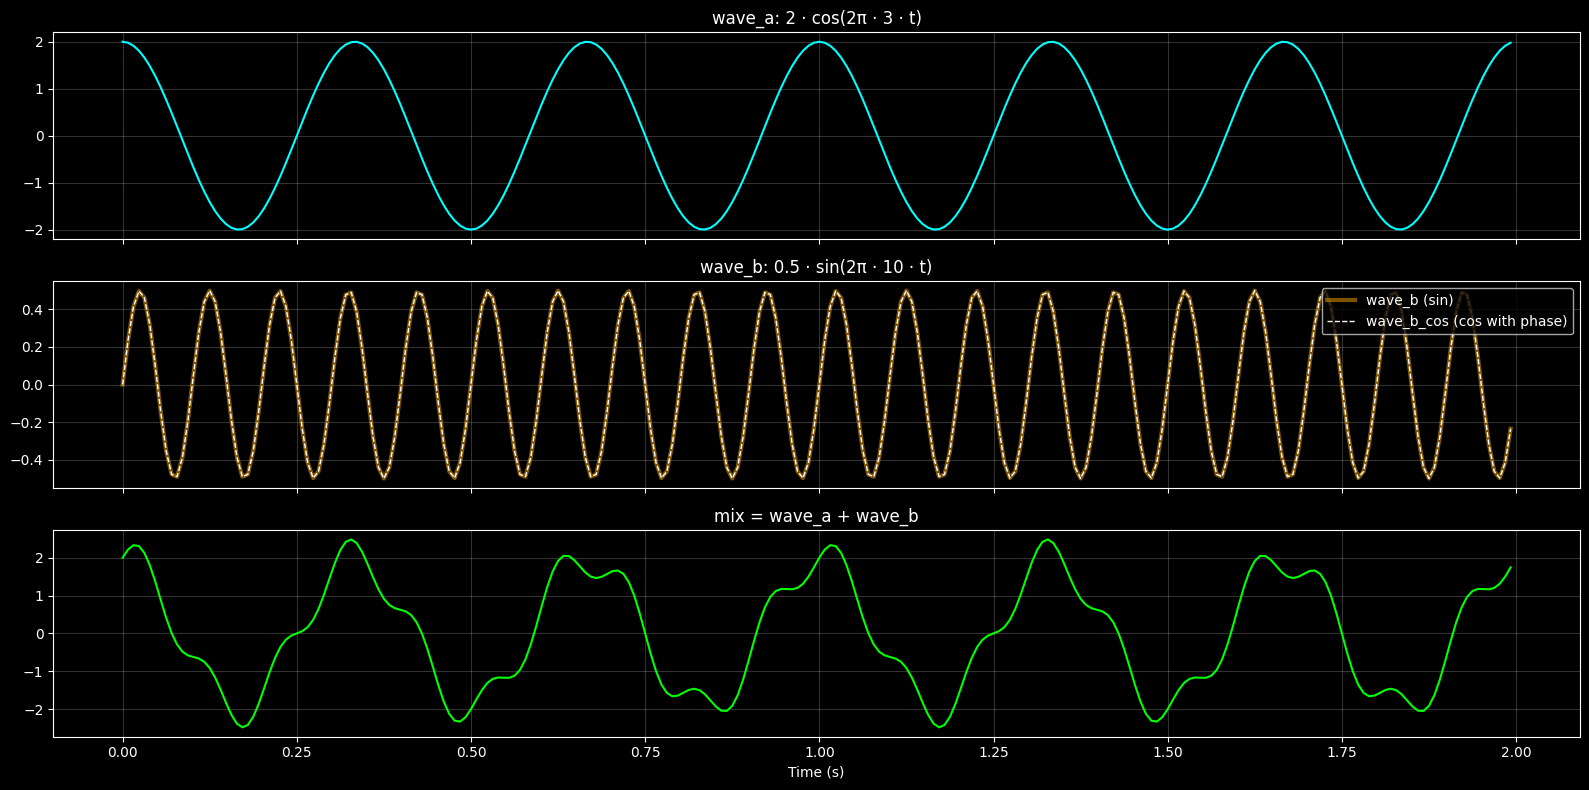

In [6]:
# YOUR CODE HERE
fs = 128
t_p = np.arange(0, 2, 1/fs)

wave_a = 2 * np.cos(2 * np.pi * 3 * t_p)
wave_b = 0.5 * np.sin(2 * np.pi * 10 * t_p)
wave_b_cos = 0.5 * np.cos(2 * np.pi * 10 * t_p - np.pi/2)
mix = wave_a + wave_b


fig, axes = plt.subplots(3, 1, figsize=(16, 8), sharex=True)
axes[0].plot(t_p, wave_a, color='cyan')
axes[0].set_title('wave_a: 2 · cos(2π · 3 · t)')
axes[1].plot(t_p, wave_b, color='orange', linewidth=3, alpha=0.5, label='wave_b (sin)')
axes[1].plot(t_p, wave_b_cos, color='white', linewidth=1, linestyle='--', label='wave_b_cos (cos with phase)')
axes[1].set_title('wave_b: 0.5 · sin(2π · 10 · t)')
axes[1].legend(loc='upper right')
axes[2].plot(t_p, mix, color='lime')
axes[2].set_title('mix = wave_a + wave_b')
axes[2].set_xlabel('Time (s)')
for ax in axes:
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [7]:
# Tests
_t = np.arange(256) / 128
assert np.shape(t_p) == (256,) and np.allclose(t_p, _t), "t_p: 256 samples, step 1/128 s, starting at 0"
assert np.allclose(wave_a, 2 * np.cos(2 * np.pi * 3 * _t)), "wave_a: amplitude 2, 3 Hz cosine"
assert np.allclose(wave_b, 0.5 * np.sin(2 * np.pi * 10 * _t)), "wave_b: amplitude 0.5, 10 Hz sine"
assert np.allclose(wave_b_cos, wave_b), "wave_b_cos: must equal wave_b"
assert np.allclose(mix, wave_a + wave_b), "mix: wave_a + wave_b"
print("Practice 1 passed.")


Practice 1 passed.


---

## Part 2: The Fourier Transform Step by Step

**Main idea:** any signal, however messy, is a sum of simple waves with different frequencies, amplitudes and phases. It is like saying 9 = 3 + 6: the 9 is hard to read, the 3 and the 6 are easy.

The Fourier transform answers one question: *which waves were added together to make this signal, and how big is each one?*

### Example 2a: complex numbers = arrows

A complex number is just a convenient way to store an arrow: the real part is the x-shadow (cos), the imaginary part is the y-shadow (sin). Euler's formula says exactly this:

`e^{iθ} = cos θ + i · sin θ`

- `A · e^{iθ}` is an arrow of length `A` at angle `θ`.
- Multiplying by `e^{iθ}` turns an arrow by θ. For example `e^{iπ} = −1` (half a turn).
- `e^{i2πft}` is an arrow spinning `f` times per second. We call it a **complex sine wave**.

e^(iπ)   = -1.000+0.000j
e^(iπ/2) = 0.000+1.000j
z = 2·e^(iπ/6) = 1.732+1.000j  →  |z| = 2.000, angle = 0.5236 rad = 30.0°
z rotated by 90°: -1.000+1.732j, angle = 120.0°


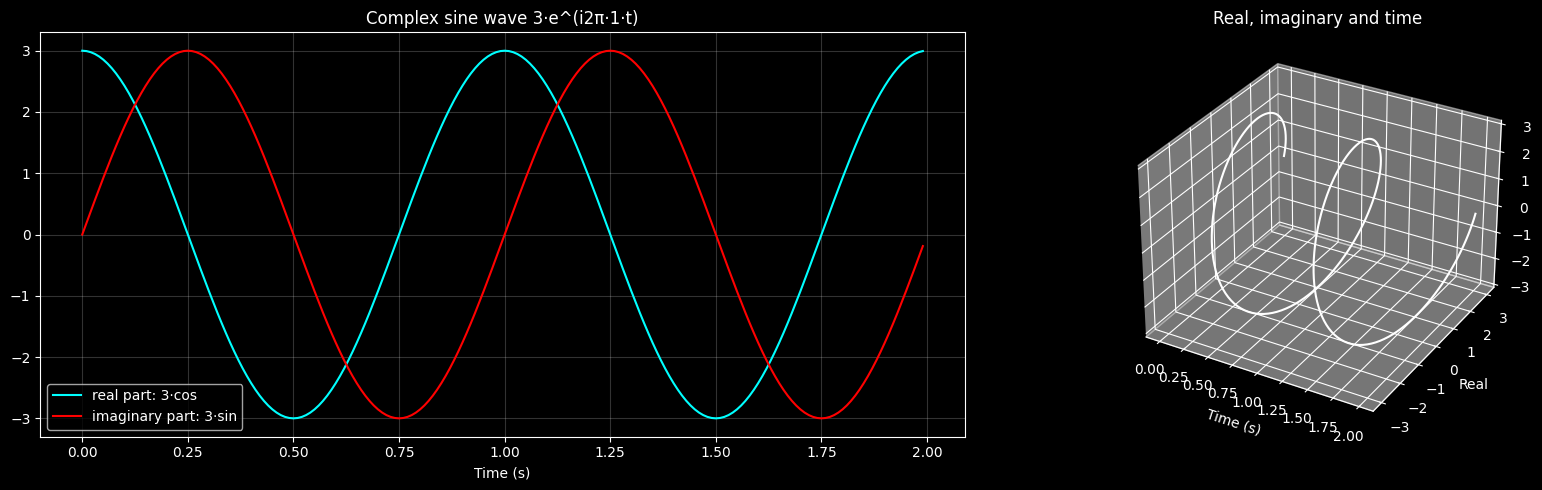

In [8]:
print(f"e^(iπ)   = {np.exp(1j * np.pi):.3f}")
print(f"e^(iπ/2) = {np.exp(1j * np.pi / 2):.3f}")
z = 2 * np.exp(1j * np.pi / 6)
print(f"z = 2·e^(iπ/6) = {z:.3f}  →  |z| = {np.abs(z):.3f}, angle = {np.angle(z):.4f} rad = {np.rad2deg(np.angle(z)):.1f}°")
print(f"z rotated by 90°: {z * np.exp(1j * np.pi / 2):.3f}, angle = {np.rad2deg(np.angle(z * np.exp(1j * np.pi / 2))):.1f}°")

amp, f = 3, 1
csw = amp * np.exp(1j * 2 * np.pi * f * t)       # t: 2 s at 100 Hz from Example 1c

fig = plt.figure(figsize=(18, 5))
ax0 = fig.add_subplot(1, 2, 1)
ax0.plot(t, csw.real, color='cyan', label='real part: 3·cos')
ax0.plot(t, csw.imag, color='red', label='imaginary part: 3·sin')
ax0.set_xlabel('Time (s)')
ax0.set_title('Complex sine wave 3·e^(i2π·1·t)')
ax0.legend(loc='lower left')
ax0.grid(True, alpha=0.2)
ax1 = fig.add_subplot(1, 2, 2, projection='3d')
ax1.plot(t, csw.real, csw.imag, color='white')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Real')
ax1.set_zlabel('Imaginary')
ax1.set_title('Real, imaginary and time')
plt.tight_layout()
plt.show()

### Example 2b: the Fourier coefficients

We build a test signal ourselves, so we already know the answer and can check it:

`signal = 1 + 2·sin(2π·4t) + 1·cos(2π·10t + π/4)`

(a constant of 1, a 4 Hz wave of size 2, and a 10 Hz wave of size 1).

**Recipe**, repeated for every frequency `fi = 0, 1, 2, ...`:

1. Make an arrow that spins *backwards* at that frequency: `e^{−i2π·fi·t}`.
2. Multiply it with the signal and add everything up. The part of the signal that spins at `fi` is now "frozen" and adds up; all other frequencies keep spinning and cancel out.
3. Divide by the number of samples `N`.

Here the signal is exactly 1 s long, so frequency number `fi` is simply `fi` Hz.

The result is one complex number per frequency (a **Fourier coefficient**). Its length tells how big that wave is (**amplitude**), its angle tells where the wave starts (**phase**).

N = 100, 51 frequencies from 0 to 50.0 Hz, resolution 1.0 Hz
loop result equals np.fft.fft(signal) / N: True

  0.0 Hz: amplitude = 1.000, phase =     0.0°
  4.0 Hz: amplitude = 2.000, phase =   -90.0°
 10.0 Hz: amplitude = 1.000, phase =    45.0°
 20.0 Hz: amplitude = 0.000, phase =  -116.6°


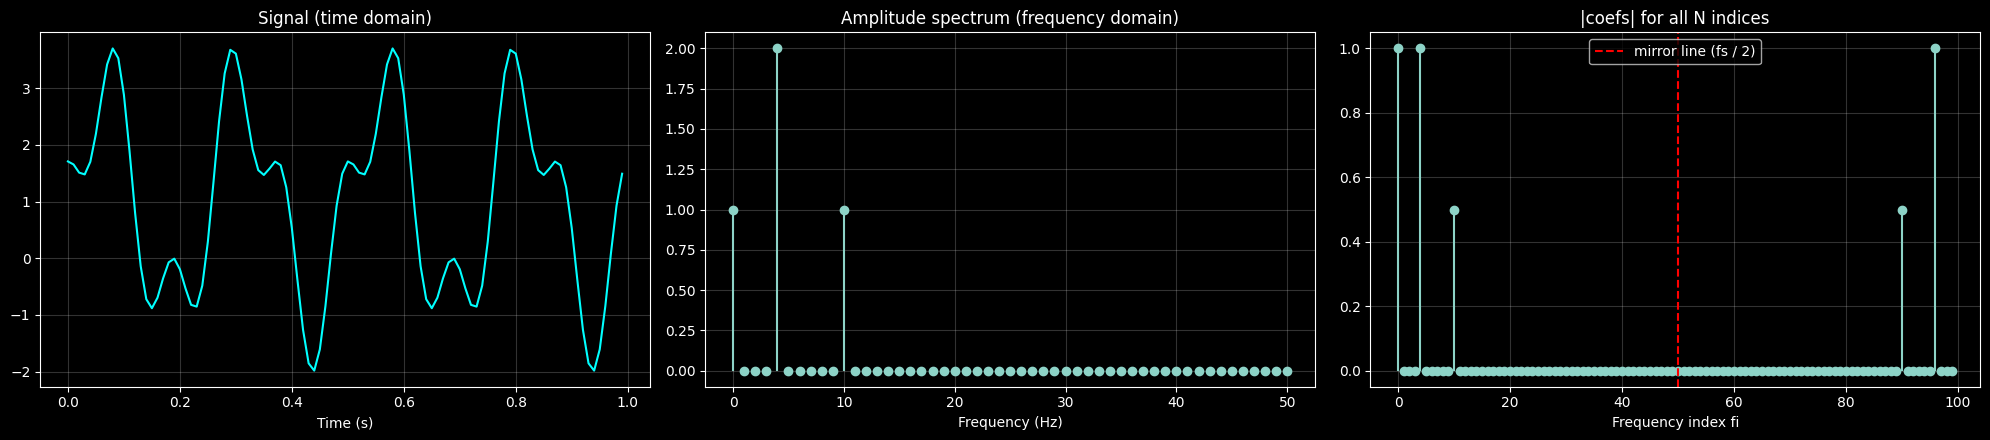

In [9]:
fs = 100
t = np.arange(0, 1, 1 / fs)
signal = 1 + 2 * np.sin(2 * np.pi * 4 * t) + 1 * np.cos(2 * np.pi * 10 * t + np.pi / 4)

N = len(signal)
four_time = np.arange(N) / N                 # normalized time: does not depend on fs
coefs = np.zeros(N, dtype=complex)
for fi in range(N):
    csw = np.exp(-1j * 2 * np.pi * fi * four_time)
    coefs[fi] = np.sum(signal * csw) / N

hz = np.linspace(0, fs / 2, N // 2 + 1)      # 0 Hz ... fs/2
amps = 2 * np.abs(coefs[:len(hz)])           # positive and negative frequency share the amplitude
amps[0] = amps[0] / 2                        # 0 Hz has no negative partner

print(f"N = {N}, {len(hz)} frequencies from 0 to {fs / 2} Hz, resolution {hz[1] - hz[0]} Hz")
print(f"loop result equals np.fft.fft(signal) / N: {np.allclose(coefs, np.fft.fft(signal) / N)}\n")
for f0 in [0, 4, 10, 20]:
    k = np.argmin(np.abs(hz - f0))
    print(f"{hz[k]:>5.1f} Hz: amplitude = {amps[k]:.3f}, phase = {np.rad2deg(np.angle(coefs[k])):7.1f}°")

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
axes[0].plot(t, signal, color='cyan')
axes[0].set_title('Signal (time domain)')
axes[0].set_xlabel('Time (s)')
axes[1].stem(hz, amps, basefmt=' ')
axes[1].set_title('Amplitude spectrum (frequency domain)')
axes[1].set_xlabel('Frequency (Hz)')
axes[2].stem(np.arange(N), np.abs(coefs), basefmt=' ')
axes[2].axvline(N / 2, color='red', linestyle='--', label='mirror line (fs / 2)')
axes[2].set_title('|coefs| for all N indices')
axes[2].set_xlabel('Frequency index fi')
axes[2].legend()
for ax in axes:
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

It works: we get back size 1 at 0 Hz, size 2 at 4 Hz and size 1 at 10 Hz, and nothing anywhere else. The phases also match (−90° because a sine is a shifted cosine, +45° = π/4). At 20 Hz the size is 0, so its phase means nothing.

The right panel looks like a mirror: the second half is a copy of the first half (the "negative frequencies"). For real signals we keep only the first half, from 0 Hz up to half the sampling rate (`fs / 2`), and multiply by 2 to count both halves (except 0 Hz, which has no copy).

### Example 2c: phase difference: adding two waves with the same frequency

One EEG electrode often picks up several brain sources that oscillate at the **same frequency**. What happens when they add up?

x₁(t) = A₁ · cos(2πft + φ₁)

x₂(t) = A₂ · cos(2πft + φ₂)

x(t) = x₁(t) + x₂(t)

- φ₁, φ₂: the **phase of each wave** (where it is in its cycle at t = 0).
- **Δφ = φ₂ − φ₁**: the **phase difference** (how far wave 2 is ahead of wave 1).

Arrow picture: both arrows spin at the same speed, so the angle between them (Δφ) never changes. Adding the waves = adding the arrows tip to tail. The result is **one** wave with the **same frequency**; only its amplitude and phase depend on Δφ.

Below: f = 5 Hz and A₁ = A₂ = 1 in every row; only Δφ changes.

Example A: same phase      Δφ =    0°   amplitude of the sum = 2.000
Example B: opposite phase  Δφ =  180°   amplitude of the sum = 0.000
Example C: quarter turn    Δφ =   90°   amplitude of the sum = 1.414


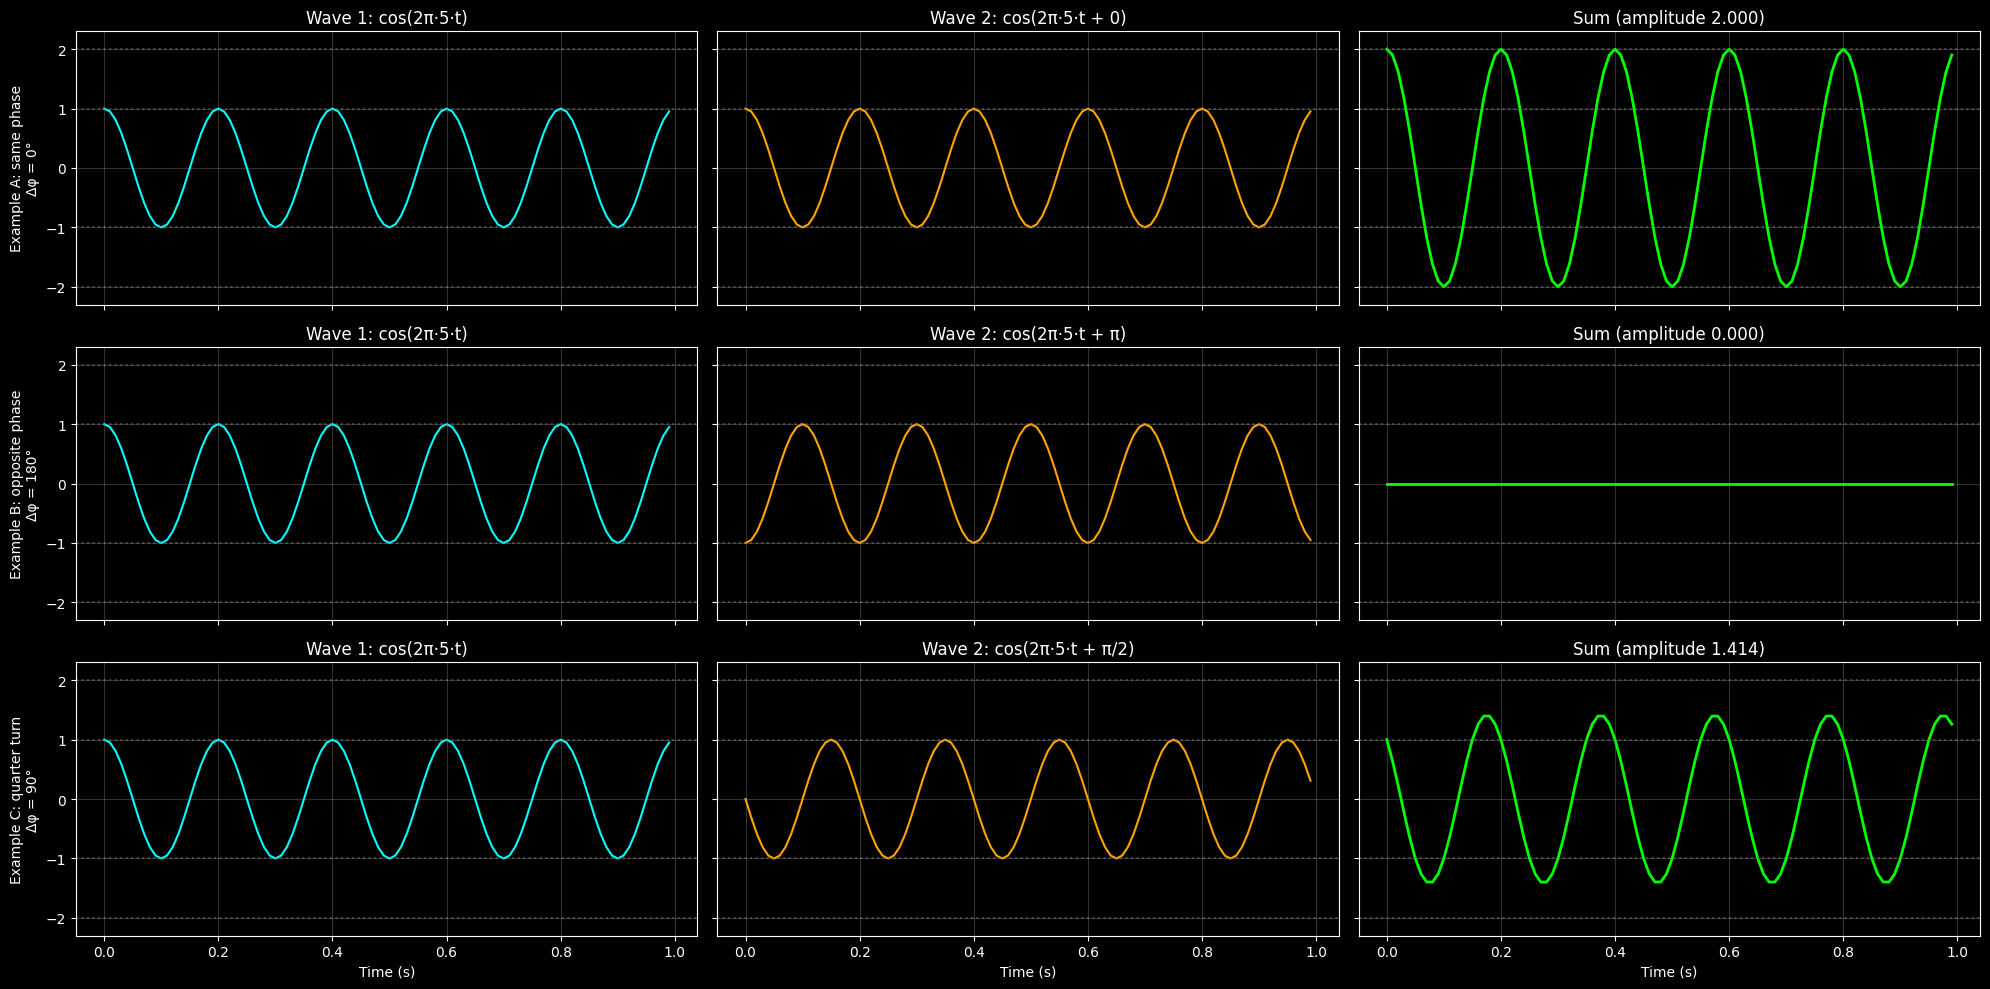


C: sum equals √2·cos(θ + π/4) on every sample: True


In [10]:
fs = 100
t = np.arange(0, 1, 1 / fs)                  # same 1 s window as Example 2b
N = len(t)
hz = np.linspace(0, fs / 2, N // 2 + 1)
f_ph = 5                                     # frequency of both waves (Hz)

def amp_at(x, f0):
    """Amplitude (2·|c|, as in Example 2b) and complex coefficient c of x at f0 Hz."""
    c = np.fft.fft(x) / N
    k = np.argmin(np.abs(hz - f0))
    return 2 * np.abs(c[k]), c[k]

theta_ph = 2 * np.pi * f_ph * t
x1 = np.cos(theta_ph)                        # wave 1: A1 = 1, φ1 = 0

examples = [                                 # (name, Δφ in radians, Δφ as text)
    ('A: same phase', 0.0, '0'),
    ('B: opposite phase', np.pi, 'π'),
    ('C: quarter turn', np.pi / 2, 'π/2'),
]

fig, axes = plt.subplots(3, 3, figsize=(20, 10), sharex=True, sharey=True)
for row, (name, dphi, dphi_text) in enumerate(examples):
    x2 = np.cos(theta_ph + dphi)             # wave 2: A2 = 1, φ2 = Δφ
    amp_sum, _ = amp_at(x1 + x2, f_ph)
    print(f"Example {name:<18} Δφ = {np.rad2deg(dphi):>4.0f}°   amplitude of the sum = {amp_sum:.3f}")

    axes[row, 0].plot(t, x1, color='cyan')
    axes[row, 0].set_title('Wave 1: cos(2π·5·t)')
    axes[row, 0].set_ylabel(f'Example {name}\nΔφ = {np.rad2deg(dphi):.0f}°')
    axes[row, 1].plot(t, x2, color='orange')
    axes[row, 1].set_title(f'Wave 2: cos(2π·5·t + {dphi_text})')
    axes[row, 2].plot(t, x1 + x2, color='lime', linewidth=2)
    axes[row, 2].set_title(f'Sum (amplitude {amp_sum:.3f})')
for ax in axes.ravel():
    for level in [-2, -1, 1, 2]:
        ax.axhline(level, color='gray', linestyle=':', alpha=0.5)
    ax.set_ylim(-2.3, 2.3)
    ax.grid(True, alpha=0.2)
for ax in axes[-1]:
    ax.set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

print(f"\nC: sum equals √2·cos(θ + π/4) on every sample: {np.allclose(x1 + np.cos(theta_ph + np.pi / 2), np.sqrt(2) * np.cos(theta_ph + np.pi / 4))}")

**What happened?** (dotted lines at ±1 and ±2)

- **A, Δφ = 0° → reinforcement.** The peaks line up: x(t) = 2·cos(2πft), twice as tall.
- **B, Δφ = 180° → cancellation.** Since cos(θ + π) = −cos(θ), whenever wave 1 is positive, wave 2 is equally negative. The sum is 0 at **every** moment (destructive interference).
- **C, Δφ = 90° → in between.** When one wave is at its peak, the other is at 0. Using cos(θ + π/2) = −sin(θ): x(t) = cos(θ) − sin(θ) = **√2·cos(θ + π/4)**, a 5 Hz wave with amplitude √2 ≈ 1.414 and phase 45°.

**General rule** for two waves with the same frequency:

A_result = √(A₁² + A₂² + 2·A₁·A₂·cos(Δφ))

This is just the length of the two arrows added tip to tail. Only `cos(Δφ)` depends on the phase:

| Δφ | cos(Δφ) | A₁ = A₂ = 1 | |
|---|---|---|---|
| 0° | +1 | √4 = **2** | maximum reinforcement |
| 90° | 0 | √2 ≈ **1.414** | partial reinforcement |
| 180° | −1 | √0 = **0** | maximum cancellation |

Perfect cancellation needs **equal amplitudes** and Δφ = 180°. With A₁ = 1, A₂ = 0.6 at 180°: √(1 + 0.36 − 1.2) = **0.4**, not 0.

### What does the Fourier transform see?

At each frequency the transform gives one complex coefficient `c` (Example 2b): **2·|c| = amplitude**, **angle of c = phase**. Its real part measures the cosine part of the wave and its imaginary part the sine part, so the phase is kept, not thrown away.

The coefficients of a sum are the sum of the coefficients: **c(x₁ + x₂) = c(x₁) + c(x₂)**. At 5 Hz the two arrows `c₁` and `c₂` add tip to tail, so they reinforce or cancel exactly like the waves.

Don't confuse the two "phases":

- **Δφ** compares wave 2 with wave 1. It does not depend on when the recording starts.
- **`np.angle(c)`** compares the (summed) wave with a cosine starting at the first sample of the window. Start the window later and it changes.

Top row: arrows `2·c₁`, `2·c₂` and `2·c_sum` (×2 so that length = amplitude). Bottom row: the spectrum of the sum.

Example A: same phase      c1 + c2 equals c_sum: True   amplitude = 2.000, phase = 0°
Example B: opposite phase  c1 + c2 equals c_sum: True   amplitude = 0.000, phase = none (no wave left)
Example C: quarter turn    c1 + c2 equals c_sum: True   amplitude = 1.414, phase = 45°


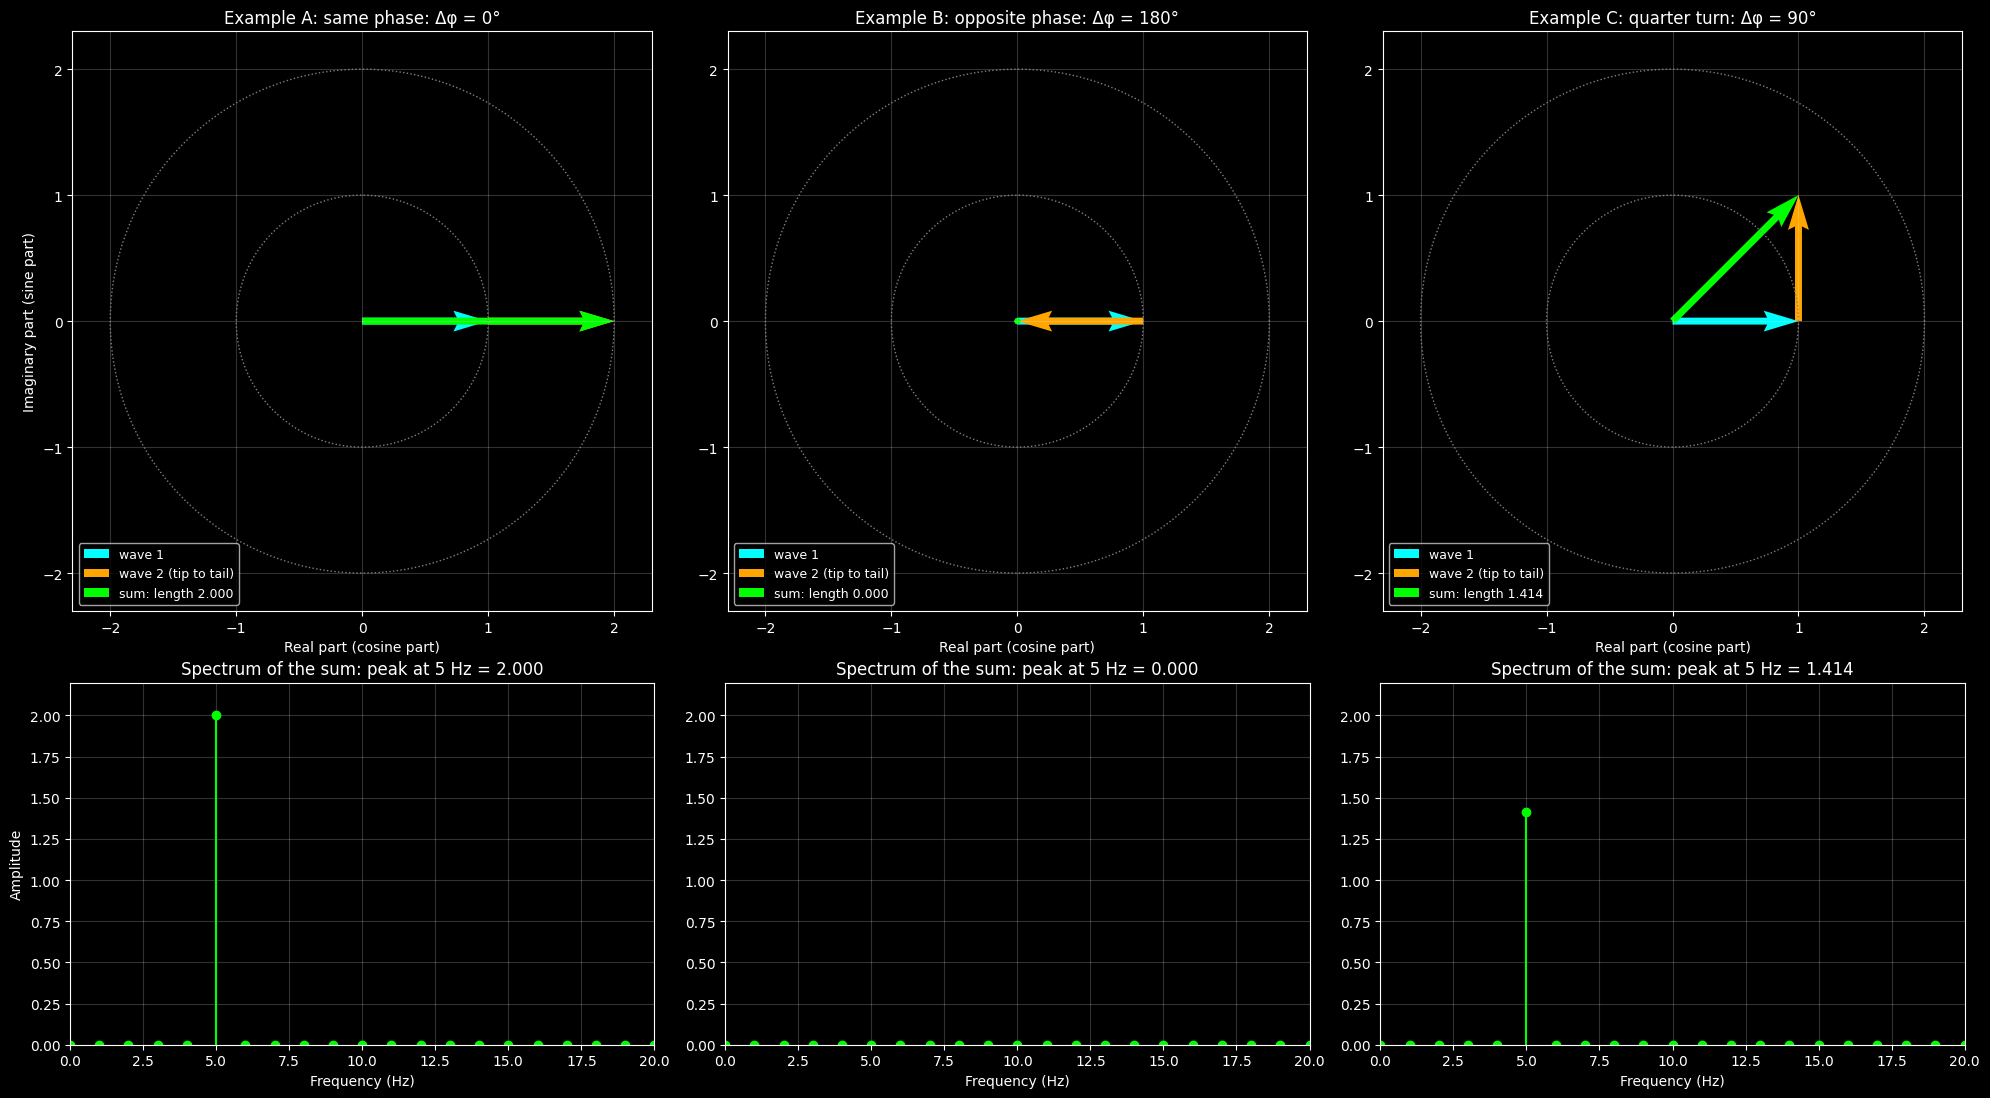

In [11]:
circle = np.linspace(0, 2 * np.pi, 400)
arrow = dict(angles='xy', scale_units='xy', scale=1, width=0.012)

def draw_arrows(ax, v1, v2):
    """Draw v1, v2 tip to tail and their sum in the complex plane."""
    for radius in [1, 2]:
        ax.plot(radius * np.cos(circle), radius * np.sin(circle), color='gray', linestyle=':', linewidth=1)
    ax.quiver(0, 0, v1.real, v1.imag, color='cyan', label='wave 1', **arrow)
    ax.quiver(v1.real, v1.imag, v2.real, v2.imag, color='orange', label='wave 2 (tip to tail)', **arrow)
    ax.quiver(0, 0, (v1 + v2).real, (v1 + v2).imag, color='lime', label=f'sum: length {abs(v1 + v2):.3f}', **arrow)
    ax.set_aspect('equal')
    ax.set_xlim(-2.3, 2.3)
    ax.set_ylim(-2.3, 2.3)
    ax.set_xlabel('Real part (cosine part)')
    ax.grid(True, alpha=0.2)

fig, axes = plt.subplots(2, 3, figsize=(20, 11), gridspec_kw={'height_ratios': [1.6, 1]})
for col, (name, dphi, dphi_text) in enumerate(examples):
    x2 = np.cos(theta_ph + dphi)
    _, c1 = amp_at(x1, f_ph)
    _, c2 = amp_at(x2, f_ph)
    amp_sum, c_sum = amp_at(x1 + x2, f_ph)
    phase_text = f"{np.round(np.rad2deg(np.angle(c_sum))) + 0.0:.0f}°" if amp_sum > 1e-9 else "none (no wave left)"
    print(f"Example {name:<18} c1 + c2 equals c_sum: {np.isclose(c1 + c2, c_sum)}   amplitude = {amp_sum:.3f}, phase = {phase_text}")

    draw_arrows(axes[0, col], 2 * c1, 2 * c2)
    axes[0, col].set_title(f'Example {name}: Δφ = {np.rad2deg(dphi):.0f}°')
    axes[0, col].legend(loc='lower left', fontsize=9)

    amps_sum = 2 * np.abs(np.fft.fft(x1 + x2)[:len(hz)] / N)
    axes[1, col].stem(hz, amps_sum, linefmt='lime', markerfmt='o', basefmt=' ')
    axes[1, col].set_xlim(0, 20)
    axes[1, col].set_ylim(0, 2.2)
    axes[1, col].set_xlabel('Frequency (Hz)')
    axes[1, col].set_title(f'Spectrum of the sum: peak at 5 Hz = {amp_sum:.3f}')
    axes[1, col].grid(True, alpha=0.2)
axes[0, 0].set_ylabel('Imaginary part (sine part)')
axes[1, 0].set_ylabel('Amplitude')
plt.tight_layout()
plt.show()

- **A:** same direction → the green arrow is 2 long.
- **B:** opposite directions → no green arrow (length 0), and **no peak** in the spectrum, although two waves are there.
- **C:** right angle → the green arrow is the diagonal of a square: √2 ≈ 1.414 at 45°, the same as √2·cos(θ + π/4).

Both waves have the same frequency, so they fall into the **same** frequency bin: the spectrum always shows **one** peak, the sum. The Fourier transform cannot tell that two sources were there or how big each one was.

### Try it yourself: change the phase difference

Frequency (5 Hz) and amplitudes (1 and 1) stay fixed; only Δφ changes. With `ipywidgets` installed you get a slider; otherwise change `delta_deg` and run the cell again.

The title compares the amplitude **predicted** by the formula with the one **measured** by the FFT. They match here because 5 Hz fits exactly 5 times in the 1 s window. With a frequency that falls between two FFT bins (e.g. 5.5 Hz), the measured value would be a bit lower.

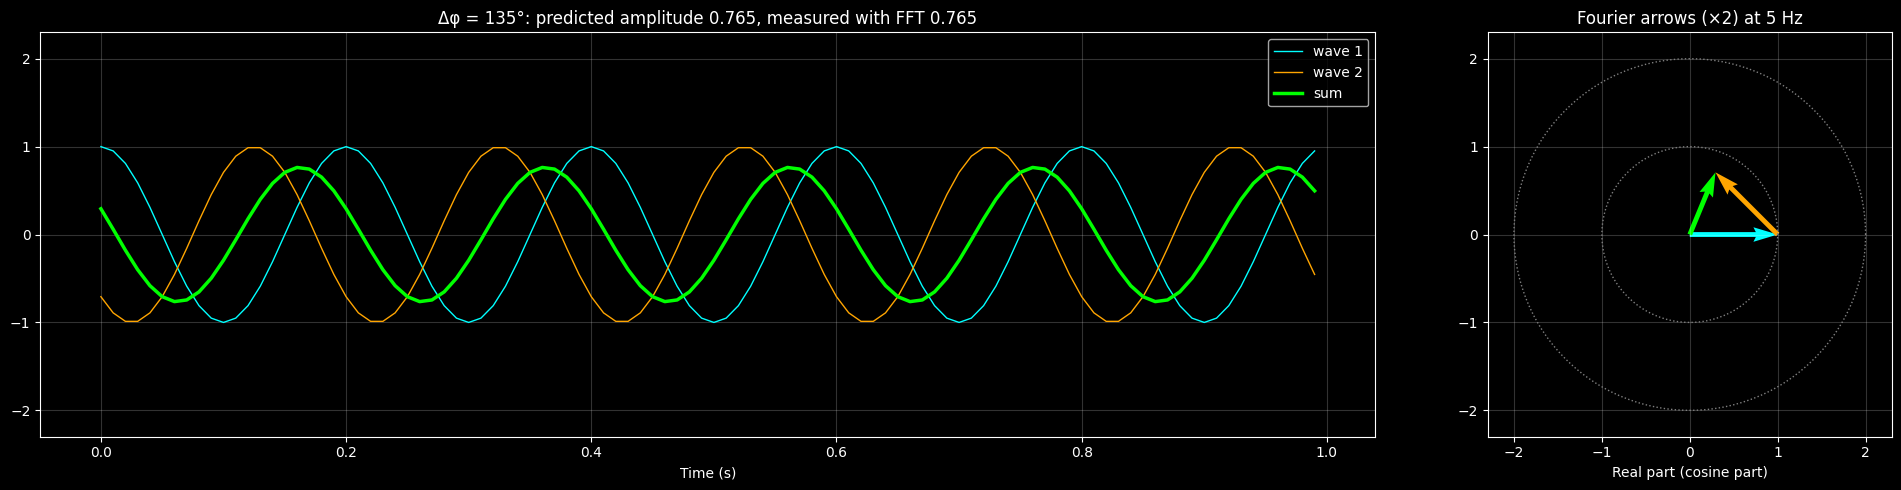

In [12]:
A1, A2 = 1.0, 1.0                            # fixed amplitudes; only Δφ changes

def phase_experiment(delta_deg=90):
    dphi = np.deg2rad(delta_deg)
    w1 = A1 * np.cos(theta_ph)
    w2 = A2 * np.cos(theta_ph + dphi)
    predicted = np.sqrt(A1**2 + A2**2 + 2 * A1 * A2 * np.cos(dphi))
    measured, _ = amp_at(w1 + w2, f_ph)

    fig, axes = plt.subplots(1, 2, figsize=(20, 5), gridspec_kw={'width_ratios': [2.3, 1]})
    axes[0].plot(t, w1, color='cyan', linewidth=1, label='wave 1')
    axes[0].plot(t, w2, color='orange', linewidth=1, label='wave 2')
    axes[0].plot(t, w1 + w2, color='lime', linewidth=2.5, label='sum')
    axes[0].set_ylim(-2.3, 2.3)
    axes[0].set_xlabel('Time (s)')
    axes[0].set_title(f'Δφ = {delta_deg}°: predicted amplitude {predicted:.3f}, measured with FFT {measured:.3f}')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, alpha=0.2)
    draw_arrows(axes[1], 2 * amp_at(w1, f_ph)[1], 2 * amp_at(w2, f_ph)[1])
    axes[1].set_title('Fourier arrows (×2) at 5 Hz')
    plt.tight_layout()
    plt.show()

try:
    from ipywidgets import interact, IntSlider
    interact(phase_experiment, delta_deg=IntSlider(value=90, min=0, max=360, step=5, description='Δφ (°)'))
except ImportError:
    delta_deg = 135                          # change me (0 – 360) and run again
    phase_experiment(delta_deg)

### Practice 2 (12 min)

The signal `mystery` (2 s, 200 samples per second) is a constant + two waves + some noise. Use the Fourier transform to find the two hidden frequencies. Hint: copy the code of Example 2b and change the names.

1. `N_m`: the number of samples. `coefs_m`: the Fourier coefficients (same loop as Example 2b, divided by `N_m`).
2. `hz_m`: the frequencies in Hz, from 0 to `fs_m / 2` (`N_m // 2 + 1` values).
3. `amps_m`: the amplitudes (2 × |coefs|, but not doubled at 0 Hz).
4. `peak_freqs`: the two frequencies with the biggest amplitudes (ignore 0 Hz), sorted from small to big.

In [13]:
rng = np.random.default_rng(7)
fs_m = 200
t_m = np.arange(0, 2, 1 / fs_m)
mystery = (0.5 + 1.5 * np.cos(2 * np.pi * 6 * t_m + 1.0) + 0.8 * np.sin(2 * np.pi * 22 * t_m)
           + 0.3 * rng.standard_normal(len(t_m)))
print(f"mystery: {mystery.shape}")

mystery: (400,)


frequency resolution: 0.5 Hz
0 Hz: 0.468
6.0 Hz: amplitude = 1.505, phase = 0.987 rad
22.0 Hz: amplitude = 0.826, phase = -1.597 rad


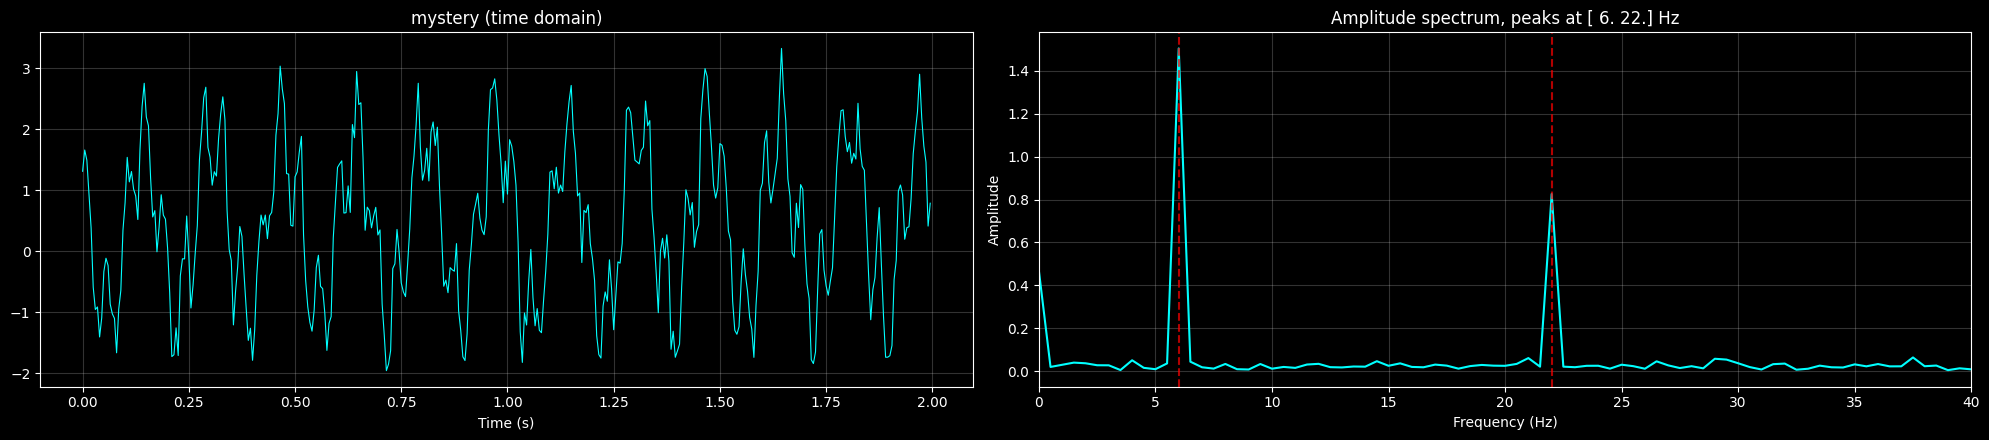

In [14]:
# YOUR CODE HERE

# 1. Number of samples
N_m = len(mystery)

# 2. Fourier coefficients
coefs_m = np.fft.fft(mystery) / N_m

# 3. Frequency values: 0 Hz to Nyquist frequency
hz_m = np.linspace(0, fs_m / 2, N_m // 2 + 1)

# 4. Calculate the one-sided amplitude spectrum
amps_m = 2 * np.abs(coefs_m[:len(hz_m)])
amps_m[0] /= 2  # Don't double the constant component

# 5. Find the two strongest non-zero frequencies
peak_indices = np.argsort(amps_m[1:])[-2:] + 1
peak_freqs = np.sort(hz_m[peak_indices])



print(f"frequency resolution: {hz_m[1] - hz_m[0]} Hz")
print(f"0 Hz: {amps_m[0]:.3f}")
for f0 in peak_freqs:
    k = np.argmin(np.abs(hz_m - f0))
    print(f"{f0:.1f} Hz: amplitude = {amps_m[k]:.3f}, phase = {np.angle(coefs_m[k]):.3f} rad")

fig, axes = plt.subplots(1, 2, figsize=(20, 4.5))
axes[0].plot(t_m, mystery, color='cyan', linewidth=0.8)
axes[0].set_xlabel('Time (s)')
axes[0].set_title('mystery (time domain)')
axes[1].plot(hz_m, amps_m, color='cyan')
for f0 in peak_freqs:
    axes[1].axvline(f0, color='red', linestyle='--', alpha=0.7)
axes[1].set_xlim(0, 40)
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('Amplitude')
axes[1].set_title(f'Amplitude spectrum, peaks at {peak_freqs} Hz')
for ax in axes:
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [15]:
# Tests
_c = np.fft.fft(mystery) / len(mystery)
_hz = np.fft.rfftfreq(len(mystery), 1 / fs_m)
_a = 2 * np.abs(_c[:len(_hz)])
_a[0] /= 2
assert N_m == 400, "N_m: number of samples"
assert np.shape(coefs_m) == (400,) and np.allclose(coefs_m, _c), "coefs_m: sum(signal * e^(-i2π·fi·t_norm)) / N"
assert np.allclose(hz_m, _hz), "hz_m: 0 to fs/2 with N//2 + 1 points"
assert np.allclose(amps_m, _a), "amps_m: 2·|coefs| except 0 Hz"
assert np.allclose(peak_freqs, [6, 22]), "peak_freqs: the two largest peaks above 0 Hz, sorted"
print("Practice 2 passed.")


Practice 2 passed.


Our loop is slow for long signals. `np.fft.fft` (the **Fast Fourier Transform**, FFT) gives exactly the same numbers, much faster. From now on we use it.

---

## Part 3: The Fourier Transform on Real EEG

Same data as Week 2: one person imagined moving the left or the right hand.

- Each trial lasts 9 s: rest (0 – 2 s), beep (2 s), arrow on the screen (3 s), then imagining the movement until 9 s.
- 3 electrodes: C3 (left side of the head), Cz (middle), C4 (right side). 128 samples per second. The recording was filtered to keep only 0.5 – 30 Hz.
- 140 trials: 70 LEFT (label 1) and 70 RIGHT (label 2).

In [16]:
DATA_FILE = 'dataset_BCIcomp1.mat'
DATA_URL = 'https://raw.githubusercontent.com/bhoom10/bci-media-player/master/dataset_BCIcomp1.mat'
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

mat = loadmat(DATA_FILE)
X = np.transpose(mat['x_train'], (2, 1, 0))      # (trials, channels, time)
y = mat['y_train'].ravel()

fs = 128
channel_names = ['C3', 'Cz', 'C4']
class_names = {1: 'LEFT', 2: 'RIGHT'}
class_colors = {1: 'cyan', 2: 'orange'}
n_trials, n_channels, n_times = X.shape
times = np.arange(n_times) / fs
print(f"X: {X.shape}  (trials, channels, time), y: {y.shape}")

X: (140, 3, 1152)  (trials, channels, time), y: (140,)


### Example 3a: spectrum of one EEG trial

The function `amplitude_spectrum` does the same thing as Example 2b, but with the FFT. It works on one signal or on all trials and channels at once.

Useful rule: the longer the piece of signal, the finer the frequency steps. Steps = 1 / (length in seconds), so 4 s gives steps of 0.25 Hz.

segment: 512 samples = 4.0 s → resolution 0.25 Hz
FFT equals the loop: True
largest peak above 3 Hz: 10.25 Hz


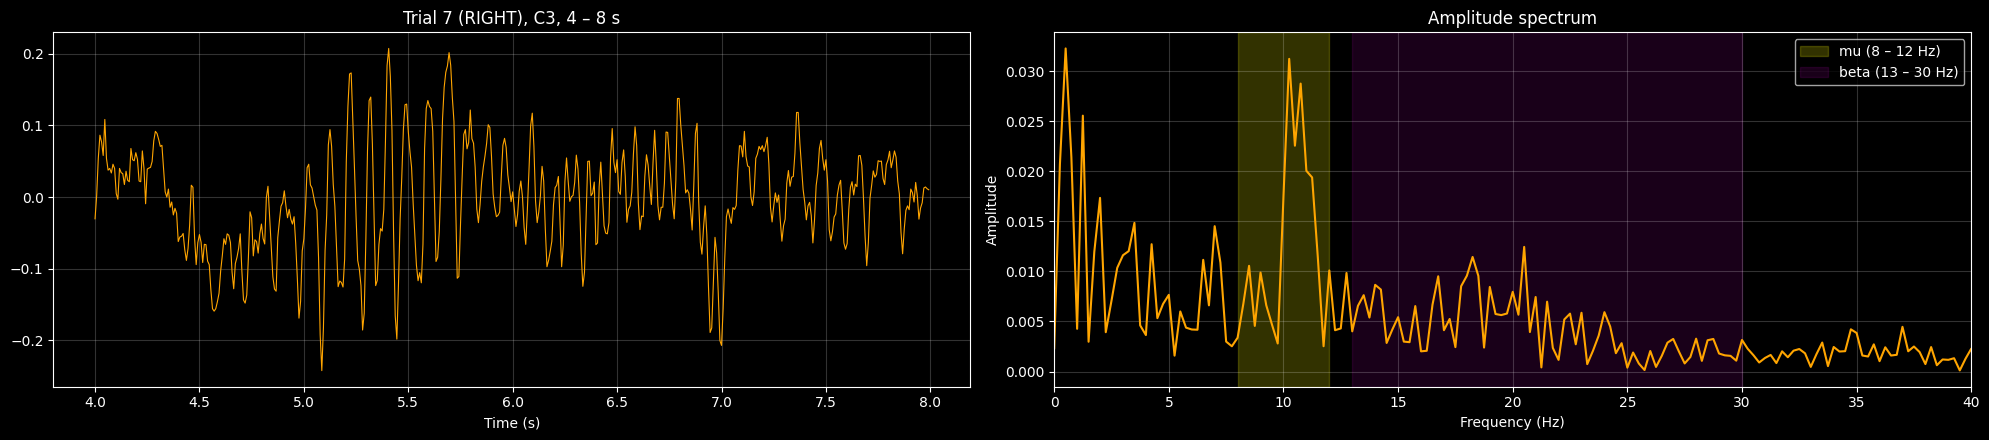

In [17]:
def amplitude_spectrum(x, fs):
    """One-sided amplitude spectrum along the last axis."""
    n = x.shape[-1]
    coefs = np.fft.fft(x, axis=-1) / n
    hz = np.linspace(0, fs / 2, n // 2 + 1)
    amps = 2 * np.abs(coefs[..., :len(hz)])
    amps[..., 0] = amps[..., 0] / 2
    return hz, amps

trial = 7
window = (times >= 4) & (times < 8)              # 4 s of motor imagery
seg = X[trial, 0, window]
hz_eeg, amps_eeg = amplitude_spectrum(seg, fs)

seg_coefs = np.array([np.sum(seg * np.exp(-1j * 2 * np.pi * fi * np.arange(len(seg)) / len(seg))) for fi in range(len(seg))]) / len(seg)
print(f"segment: {seg.shape[0]} samples = {seg.shape[0] / fs} s → resolution {hz_eeg[1]} Hz")
print(f"FFT equals the loop: {np.allclose(np.fft.fft(seg) / len(seg), seg_coefs)}")
above_3 = hz_eeg > 3                             # skip the slow drift near 0 Hz
print(f"largest peak above 3 Hz: {hz_eeg[above_3][np.argmax(amps_eeg[above_3])]:.2f} Hz")

fig, axes = plt.subplots(1, 2, figsize=(20, 4.5))
axes[0].plot(times[window], seg, color=class_colors[y[trial]], linewidth=0.8)
axes[0].set_xlabel('Time (s)')
axes[0].set_title(f'Trial {trial} ({class_names[y[trial]]}), C3, 4 – 8 s')
axes[1].plot(hz_eeg, amps_eeg, color=class_colors[y[trial]])
axes[1].axvspan(8, 12, color='yellow', alpha=0.2, label='mu (8 – 12 Hz)')
axes[1].axvspan(13, 30, color='magenta', alpha=0.1, label='beta (13 – 30 Hz)')
axes[1].set_xlim(0, 40)
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('Amplitude')
axes[1].set_title('Amplitude spectrum')
axes[1].legend(loc='upper right')
for ax in axes:
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

Above 30 Hz the spectrum is almost flat at zero .. why ?

### Example 3b: average power spectrum per class

**Power** = amplitude². One trial is noisy, so we average the power of all LEFT trials, and of all RIGHT trials (`axis=0`, like in Week 2).

Order matters: first the spectrum of each trial, then the average. (If we averaged the raw signals first, the waves would cancel each other out.)

What to expect: the brain has a rhythm around 8 – 12 Hz over the movement areas, called the **mu rhythm**. When you imagine moving a hand, this rhythm gets *weaker* on the **opposite** side of the head:

- imagine the RIGHT hand → mu power drops at C3 (left side)
- imagine the LEFT hand → mu power drops at C4 (right side)

amps_all: (140, 3, 257)  (trials, channels, frequencies)


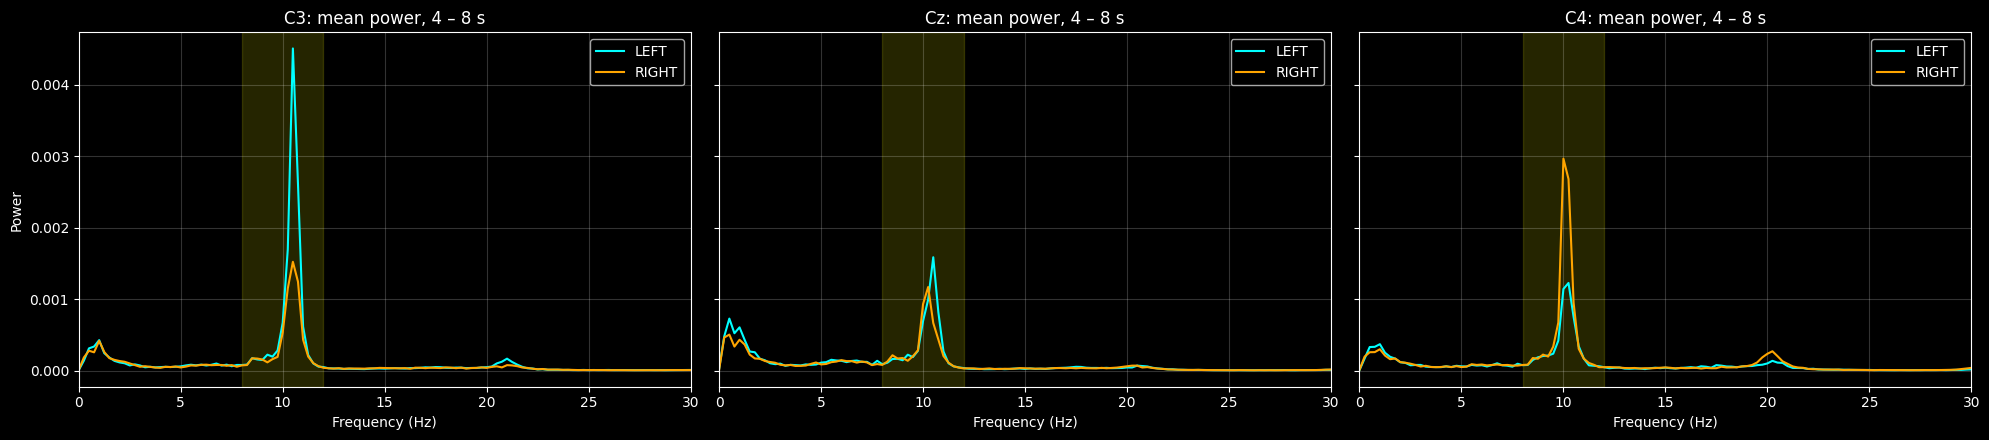

In [18]:
hz_eeg, amps_all = amplitude_spectrum(X[:, :, window], fs)    # (140, 3, 257)
power_all = amps_all ** 2
print(f"amps_all: {amps_all.shape}  (trials, channels, frequencies)")

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5), sharey=True)
for c, ax in enumerate(axes):
    for label in [1, 2]:
        ax.plot(hz_eeg, power_all[y == label, c].mean(axis=0), color=class_colors[label], label=class_names[label])
    ax.axvspan(8, 12, color='yellow', alpha=0.15)
    ax.set_xlim(0, 30)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_title(f'{channel_names[c]}: mean power, 4 – 8 s')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.2)
axes[0].set_ylabel('Power')
plt.tight_layout()
plt.show()

### Practice 3 (12 min)

Does the mu power really drop when the person imagines a movement? Compare a rest window with an imagery window (both 2 s long).

1. `rest_win`: True for 0 ≤ t < 2 s. `task_win`: True for 4 ≤ t < 6 s.
2. Use `amplitude_spectrum` on `X[:, :, rest_win]` to get `hz_p` and the amplitudes, then square them: `power_rest`, shape (140, 3, 129). Do the same for `power_task`.
3. `mu_band`: True where 8 ≤ `hz_p` ≤ 12. `mu_rest` and `mu_task`: the average power inside the mu band, shape (140, 3).
4. `erd_class`: shape (2, 3). For each class (row 0 LEFT, row 1 RIGHT) and each channel: average `mu_rest` and `mu_task` over the trials of that class, then compute the change in percent: `100 · (task − rest) / rest`.

In [ ]:
# YOUR CODE HERE





print(f"power_rest: {power_rest.shape}, mu bins: {hz_p[mu_band]}")
print(f"\n{'':<7}" + ''.join(f"{name:>10}" for name in channel_names))
for row, label in enumerate([1, 2]):
    print(f"{class_names[label]:<7}" + ''.join(f"{v:>9.1f}%" for v in erd_class[row]))

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.35
for row, label in enumerate([1, 2]):
    ax.bar(np.arange(3) + (row - 0.5) * width, erd_class[row], width, color=class_colors[label], label=class_names[label])
ax.axhline(0, color='white', linewidth=1)
ax.set_xticks(np.arange(3))
ax.set_xticklabels(channel_names)
ax.set_ylabel('mu power change from rest (%)')
ax.set_title('Mu power: imagery (4 – 6 s) vs rest (0 – 2 s)')
ax.legend()
ax.grid(True, alpha=0.2, axis='y')
plt.tight_layout()
plt.show()

In [ ]:
# Tests
_rw, _tw = times < 2, (times >= 4) & (times < 6)
_hz, _ar = amplitude_spectrum(X[:, :, _rw], fs)
_, _at = amplitude_spectrum(X[:, :, _tw], fs)
_mu = (_hz >= 8) & (_hz <= 12)
_mr, _mt = (_ar ** 2)[:, :, _mu].mean(axis=2), (_at ** 2)[:, :, _mu].mean(axis=2)
_e = np.array([100 * (_mt[y == l].mean(axis=0) - _mr[y == l].mean(axis=0)) / _mr[y == l].mean(axis=0) for l in [1, 2]])
assert rest_win.sum() == 256 and task_win.sum() == 256 and np.array_equal(task_win, _tw), "windows: 2 s = 256 samples each"
assert np.allclose(hz_p, _hz), "hz_p: 0 to 64 Hz, 129 points"
assert power_rest.shape == (140, 3, 129) and np.allclose(power_rest, _ar ** 2), "power_rest: amplitude spectrum squared"
assert np.allclose(power_task, _at ** 2), "power_task: amplitude spectrum squared"
assert np.array_equal(mu_band, _mu), "mu_band: 8 <= hz <= 12"
assert mu_rest.shape == (140, 3) and np.allclose(mu_rest, _mr) and np.allclose(mu_task, _mt), "mu_rest / mu_task: mean over the mu bins"
assert np.shape(erd_class) == (2, 3) and np.allclose(erd_class, _e), "erd_class: percent change of the class-mean mu power"
print("Practice 3 passed.")


Result: the mu power drops on the side opposite to the imagined hand (RIGHT → C3, LEFT → C4) and goes up on the same side. A BCI can use exactly this left/right difference to guess which hand the person imagined.

---

## Summary

- cos and sin are the x- and y-shadows of an arrow of length 1.
- A spinning arrow draws a wave `A · cos(2π f t + φ)`: A = size, f = speed (waves per second), φ = starting point.
- A complex number `e^{iθ}` is a handy way to write that arrow.
- The Fourier transform finds which waves are inside a signal: for each frequency it gives a size (amplitude) and a starting point (phase). `np.fft.fft` does it fast.
- Two waves with the same frequency add like arrows: same phase → stronger (2×), opposite phase → cancel (0), 90° apart → √2×. In general `A = √(A₁² + A₂² + 2A₁A₂cos Δφ)`. The FFT only sees their sum: one peak.
- On EEG: take the spectrum of each trial, then average. Imagining a hand movement lowers the mu (8 – 12 Hz) power on the opposite side of the head.